# 04 · Deep EDA

## Objective
Understand **which customer characteristics are associated with churn**, how features relate to
each other, and what this means for modelling and for the business.

All analysis uses the cleaned data from notebook 03.

> Note: EDA is done on the full cleaned dataset to understand the business. No modelling decision
> here uses statistics that are later "fitted" into the model, so this does not leak test information.
> All fitted transformations happen only on the training set (notebook 05).

In [1]:
import sys
from pathlib import Path

# Make the project root importable so we can use src/churn_utils.py
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.churn_utils import (CATEGORICAL_FEATURES, CHURN_PALETTE, CLEAN_DATA_PATH,
                             COLOR_CHURNED, NUMERIC_FEATURES, set_plot_style)

set_plot_style()
df = pd.read_csv(CLEAN_DATA_PATH)
df["churn_flag"] = df["Churn"].eq("Yes").astype(int)   # 0/1 helper for computing churn rates
overall_churn_rate = df["churn_flag"].mean()
print(df.shape, f"| overall churn rate = {overall_churn_rate:.1%}")

(7043, 21) | overall churn rate = 26.5%


## 1. Class imbalance

| | Count | Share |
|---|---|---|
| Retained (No) | 5,174 | 73.5% |
| Churned (Yes) | 1,869 | 26.5% |

(Plotted in notebook 02.) The ratio is roughly **2.8 : 1**. Implications for modelling:
- Use a **stratified** split so train and test keep the same 26.5% churn rate.
- Evaluate with recall, precision, F1 and ROC-AUC rather than accuracy.
- Consider `class_weight="balanced"` so the model doesn't simply favour the majority class.

## 2. Univariate analysis — numerical features

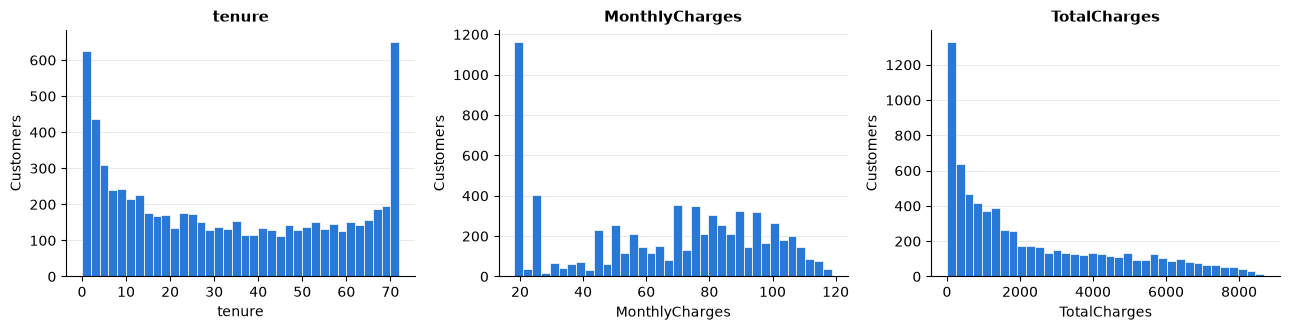

,tenure,MonthlyCharges,TotalCharges
mean,32.37,64.76,2279.73
median,29.00,70.35,1394.55
skew,0.24,-0.22,0.96


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col in zip(axes, NUMERIC_FEATURES):
    ax.hist(df[col], bins=36, color="#2a78d6", edgecolor="white", linewidth=0.5)
    ax.set(title=col, xlabel=col, ylabel="Customers")
plt.tight_layout()
plt.show()

df[NUMERIC_FEATURES].agg(["mean", "median", "skew"]).round(2)

**Observations**
- `tenure` is **U-shaped**: many very new customers (0–5 months) and a large spike at 72 months
  (long-term loyal customers; 72 is the maximum value in the data).
- `MonthlyCharges` has a tall peak around 20 (customers with phone only / no internet) and a broad
  spread from ~45 to ~110 (internet customers).
- `TotalCharges` is **right-skewed** (skew 0.96, mean 2,280 vs median 1,395) because it accumulates over tenure.
- No extreme values — standard scaling is sufficient; no log transform is needed for the tree models,
  and for logistic regression the skew is mild.

## 3. Univariate analysis — categorical features

In [3]:
# Compact summary: number of categories and how dominant the most common one is
category_summary = pd.DataFrame({
    "n_categories": df[CATEGORICAL_FEATURES].nunique(),
    "most_common": df[CATEGORICAL_FEATURES].mode().iloc[0],
    "most_common_share": df[CATEGORICAL_FEATURES].apply(lambda col: col.value_counts(normalize=True).iloc[0]).round(3),
})
category_summary.sort_values("most_common_share", ascending=False)

,n_categories,most_common,most_common_share
PhoneService,2,Yes,0.903
SeniorCitizen,2,No,0.838
Dependents,2,No,0.700
PaperlessBilling,2,Yes,0.592
Contract,3,Month-to-month,0.550
Partner,2,No,0.517
gender,2,Male,0.505
OnlineSecurity,3,No,0.497
TechSupport,3,No,0.493
MultipleLines,3,No,0.481


**Observations**
- `PhoneService` is dominated by "Yes" (90.3%) → little room to differentiate customers.
- `gender` and `Partner` are almost perfectly balanced.
- 55% of customers are on **month-to-month** contracts, 44% have **fiber optic** internet.
- 21.7% of customers have no internet service, which is why "No internet service" appears with
  the same share in all six add-on columns.

## 4. Bivariate analysis — numerical features vs churn

Density histograms (each class normalised separately) make the two groups comparable even though
there are ~2.8× more retained customers.

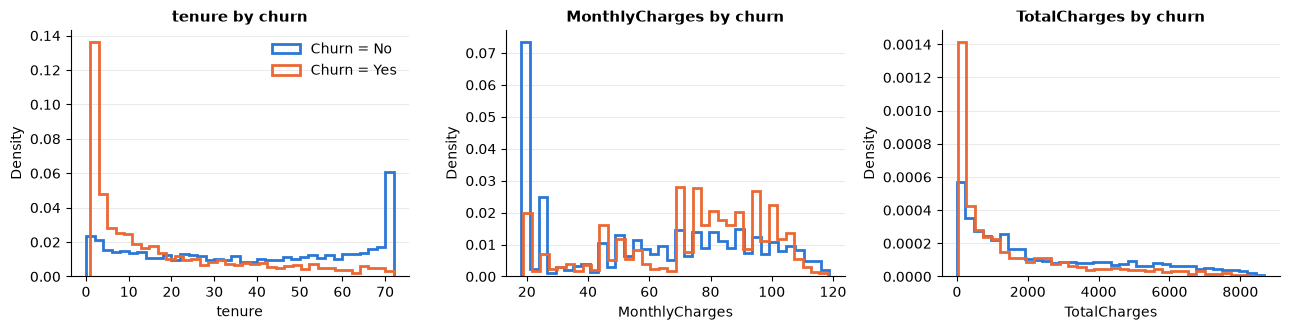

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.4,1679.5
Yes,10.0,79.6,703.6


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col in zip(axes, NUMERIC_FEATURES):
    for label in ["No", "Yes"]:
        ax.hist(df.loc[df["Churn"] == label, col], bins=36, density=True, histtype="step",
                linewidth=2, color=CHURN_PALETTE[label], label=f"Churn = {label}")
    ax.set(title=f"{col} by churn", xlabel=col, ylabel="Density")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

df.groupby("Churn")[NUMERIC_FEATURES].median().round(1)

**Observations**
- **Tenure:** churners are concentrated in the first months (median 10 vs 38 months for retained customers).
- **MonthlyCharges:** churners pay more (median 79.6 vs 64.4). The low-price peak (~20) is mostly retained customers.
- **TotalCharges:** churners have lower totals — mainly a consequence of their short tenure, not a separate effect.

In [5]:
# Churn rate across tenure bands: is the relationship linear?
tenure_bands = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 36, 48, 60, 72])
tenure_churn = df.groupby(tenure_bands, observed=True)["churn_flag"].agg(["mean", "size"])
tenure_churn.columns = ["churn_rate", "customers"]
tenure_churn.round(3)

,churn_rate,customers
tenure,,
"(-1, 6]",0.529,1481
"(6, 12]",0.359,705
"(12, 24]",0.287,1024
"(24, 36]",0.216,832
"(36, 48]",0.190,762
"(48, 60]",0.144,832
"(60, 72]",0.066,1407


**Observations**
- Churn rate falls from **52.9%** in the first 6 months to **6.6%** for customers with 61–72 months.
- The drop is steep in the first year and flattens later → the relationship is **non-linear**.
  This motivates trying a `tenure_group` feature in notebook 06 (useful for linear models).

## 5. Bivariate analysis — categorical features vs churn

For each category we plot the **churn rate**. The dashed line is the overall churn rate (26.5%):
bars far from it indicate a strong association.

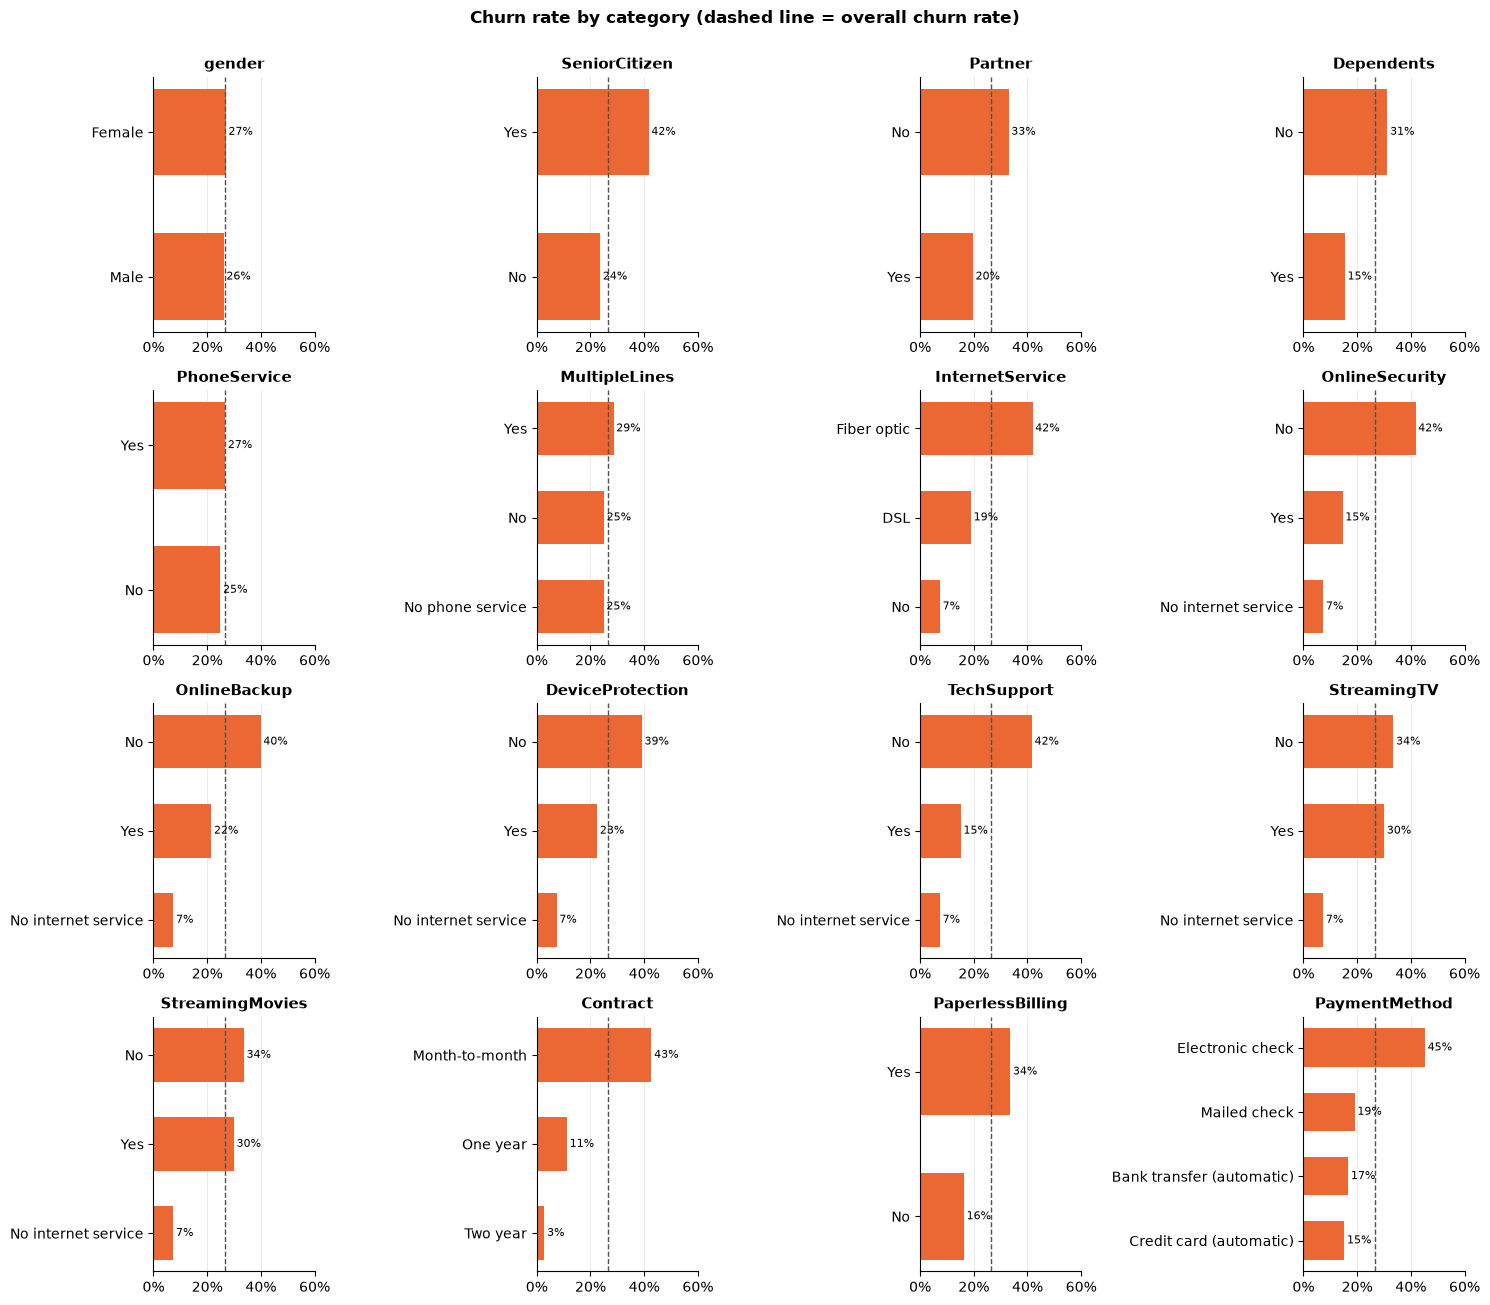

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(15, 13))
for ax, col in zip(axes.flat, CATEGORICAL_FEATURES):
    rates = df.groupby(col)["churn_flag"].mean().sort_values()
    ax.barh(rates.index.astype(str), rates.values, color=COLOR_CHURNED, height=0.6)
    ax.axvline(overall_churn_rate, color="#52514e", linestyle="--", linewidth=1)
    for y, rate in enumerate(rates.values):
        ax.text(rate + 0.01, y, f"{rate:.0%}", va="center", fontsize=8)
    ax.set(title=col, xlim=(0, 0.6))
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.suptitle("Churn rate by category (dashed line = overall churn rate)", fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

In [7]:
# Rank features by how much churn rate varies across their categories
spread = pd.DataFrame({
    col: {
        "min_churn_rate": df.groupby(col)["churn_flag"].mean().min(),
        "max_churn_rate": df.groupby(col)["churn_flag"].mean().max(),
        "highest_risk_category": df.groupby(col)["churn_flag"].mean().idxmax(),
    } for col in CATEGORICAL_FEATURES
}).T
spread["spread"] = spread["max_churn_rate"] - spread["min_churn_rate"]
spread.sort_values("spread", ascending=False).round(3)

,min_churn_rate,max_churn_rate,highest_risk_category,spread
Contract,0.028319,0.427097,Month-to-month,0.398778
InternetService,0.07405,0.418928,Fiber optic,0.344878
OnlineSecurity,0.07405,0.417667,No,0.343617
TechSupport,0.07405,0.416355,No,0.342305
OnlineBackup,0.07405,0.399288,No,0.325238
DeviceProtection,0.07405,0.391276,No,0.317226
PaymentMethod,0.152431,0.452854,Electronic check,0.300423
StreamingMovies,0.07405,0.336804,No,0.262755
StreamingTV,0.07405,0.335231,No,0.261182
SeniorCitizen,0.236062,0.416813,Yes,0.180751


**Observations** (ranked by churn-rate spread across categories)
- **Contract** is the strongest single signal: month-to-month 42.7% vs two-year 2.8%.
- **Fiber optic** internet: 41.9% churn vs 19.0% DSL and 7.4% no internet.
- **No OnlineSecurity / No TechSupport** (~42%) vs Yes (~15%). Similar but weaker for OnlineBackup and DeviceProtection.
  Part of these spreads comes from the low-churn "No internet service" group (7.4%).
- **Electronic check** payers churn at 45.3%, roughly 3× the automatic-payment methods (15–17%).
- **Senior citizens** (41.7% vs 23.6%), customers **without partner / dependents**, and **paperless billing** users churn more.
- **gender**, **PhoneService** and **MultipleLines** show almost no difference (spread < 4 points) → likely weak predictors.
  They are kept anyway: the model can down-weight them, and removing them is not needed with only 19 features.

## 6. Correlation analysis (numerical features)

Spearman correlation is used because the relationships (e.g. tenure vs TotalCharges) are monotonic
but not necessarily linear, and `TotalCharges` is skewed.

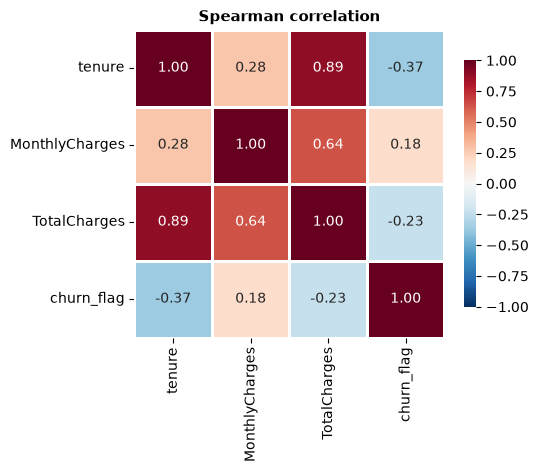

In [8]:
corr = df[NUMERIC_FEATURES + ["churn_flag"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor="white", ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Spearman correlation")
plt.show()

**Observations**
- `tenure` and `TotalCharges` are strongly correlated (ρ = 0.89): `TotalCharges` ≈ tenure × monthly charge.
  This **multicollinearity** can make logistic-regression coefficients unstable/hard to interpret, but does
  not hurt prediction much. Both are kept; regularisation (default in scikit-learn's LogisticRegression) helps.
- Churn correlates negatively with `tenure` (−0.37) and positively but weakly with `MonthlyCharges` (+0.18).

## 7. Multivariate analysis

### 7.1 Contract × tenure
Contract type and tenure were the two strongest signals. Are they telling the same story, or does
each add information?

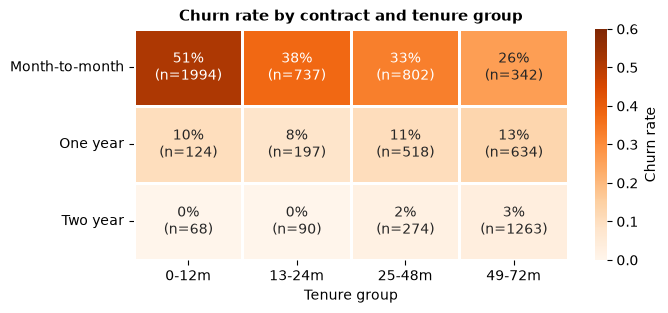

In [9]:
tenure_group = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12m", "13-24m", "25-48m", "49-72m"])
pivot = df.pivot_table(index="Contract", columns=tenure_group, values="churn_flag", aggfunc="mean", observed=True)
counts = df.pivot_table(index="Contract", columns=tenure_group, values="churn_flag", aggfunc="size", observed=True)

fig, ax = plt.subplots(figsize=(7, 3))
sns.heatmap(pivot, annot=pivot.map(lambda v: f"{v:.0%}") + "\n(n=" + counts.astype(str) + ")",
            fmt="", cmap="Oranges", vmin=0, vmax=0.6, linewidths=2, linecolor="white", ax=ax,
            cbar_kws={"label": "Churn rate"})
ax.set(title="Churn rate by contract and tenure group", xlabel="Tenure group", ylabel="")
plt.show()

**Observations**
- Contract and tenure each add information: **within month-to-month contracts** churn still falls from
  51% (0–12 months) to 26% (49–72 months), and within every tenure group, longer contracts churn far less.
- New month-to-month customers (n = 1,994) are the highest-risk segment in the data (51% churn).
- Two-year contracts have almost no churn in any tenure group (0–3%).

### 7.2 Internet service × charges
Fiber optic customers churn much more. Is that explained by price?

,customers,churn_rate,median_monthly_charge
InternetService,,,
DSL,2421,0.190,56.150
Fiber optic,3096,0.419,91.675
No,1526,0.074,20.150


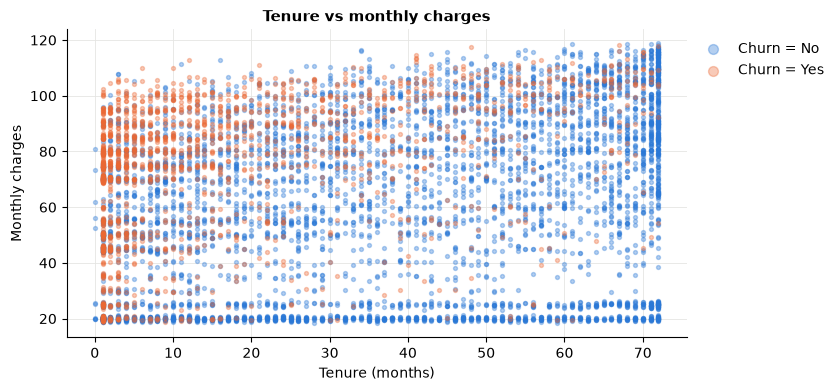

In [10]:
internet_summary = df.groupby("InternetService").agg(
    customers=("churn_flag", "size"),
    churn_rate=("churn_flag", "mean"),
    median_monthly_charge=("MonthlyCharges", "median"),
)
display(internet_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
for label in ["No", "Yes"]:
    subset = df[df["Churn"] == label]
    ax.scatter(subset["tenure"], subset["MonthlyCharges"], s=8, alpha=0.35,
               color=CHURN_PALETTE[label], label=f"Churn = {label}")
ax.set(title="Tenure vs monthly charges", xlabel="Tenure (months)", ylabel="Monthly charges")
ax.grid(axis="x")
ax.legend(frameon=False, markerscale=2.5, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()

**Observations**
- Fiber optic customers pay the most (median 91.7) and churn the most (41.9%).
- In the scatter plot, churners cluster in the **top-left: short tenure and high monthly charges**.
  Customers paying ~20/month rarely churn at any tenure.
- This suggests price / perceived value of the fiber offering matters — but this is an **association**;
  the data cannot tell us whether price *causes* churn.

In [11]:
# Among internet customers: does having TechSupport / OnlineSecurity change churn for each internet type?
internet_customers = df[df["InternetService"] != "No"]
internet_customers.pivot_table(index="InternetService",
                               columns=["TechSupport"], values="churn_flag", aggfunc="mean").round(3)

TechSupport,No,Yes
InternetService,,
DSL,0.278,0.097
Fiber optic,0.494,0.226


**Observations**
- Within both DSL and fiber, customers **with TechSupport churn much less** (fiber: 22.6% vs 49.4%).
- So the TechSupport effect is not just a side effect of internet type. It may reflect better service
  experience or simply more engaged customers (again, association rather than proven cause).

## Conclusion — key EDA findings

1. **Contract type** is the strongest churn signal (month-to-month 42.7% vs two-year 2.8%).
2. **Early tenure** is the riskiest period: 52.9% churn in the first 6 months; the relationship is non-linear.
3. **Fiber optic** customers churn the most and pay the most.
4. **Lack of protective/support add-ons** (OnlineSecurity, TechSupport) is associated with higher churn,
   even within the same internet type.
5. **Electronic check** payers churn ~3× more than automatic-payment customers.
6. `gender`, `PhoneService`, `MultipleLines` show almost no relationship with churn.
7. `tenure` and `TotalCharges` are highly correlated (0.89).

**Implications for the next steps**
- Use a stratified split and churn-focused metrics (26.5% positive class).
- Scale numeric features for distance/linear models; one-hot encode categoricals (no natural order except contract length).
- Candidate engineered features: `tenure_group` (non-linear tenure effect) and a count of add-on services.